<a href="https://colab.research.google.com/github/Adrentur/-1_-_-_-3-10/blob/main/%D0%9B%D0%A03_%D0%9F%D0%BE%D0%BB%D0%B5%D1%85%D1%96%D0%BD_3_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")





## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [ ]:
from google.colab import files
import pandas as pd


uploaded = files.upload()


file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)


display(df.head())




Saving house_price_regression_dataset.csv to house_price_regression_dataset (1).csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.





## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [ ]:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.
display(df.head())
print("\n" + "="*50 + "\n")
df.info()





,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [ ]:
# Порахуйте кількість дублікатів.
duplicates = df.duplicated().sum()
print(f"Кількість дубльованих рядків: {duplicates}")




Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [ ]:
# Виведіть кількість пропусків для кожної ознаки.
missing_values = df.isnull().sum()
print("Кількість пропущених значень:")
print(missing_values)





Кількість пропущених значень:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [ ]:
# Отримайте описову статистику датасету.
display(df.describe())





,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [ ]:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.
neighborhood_counts = df['Neighborhood_Quality'].value_counts().sort_index()
print("Частоти значень Neighborhood_Quality:")
print(neighborhood_counts)




Частоти значень Neighborhood_Quality:
Neighborhood_Quality
1      91
2     105
3      85
4      99
5     109
6     101
7     102
8      97
9      88
10    123
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

/tmp/ipykernel_5436/1574107435.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')


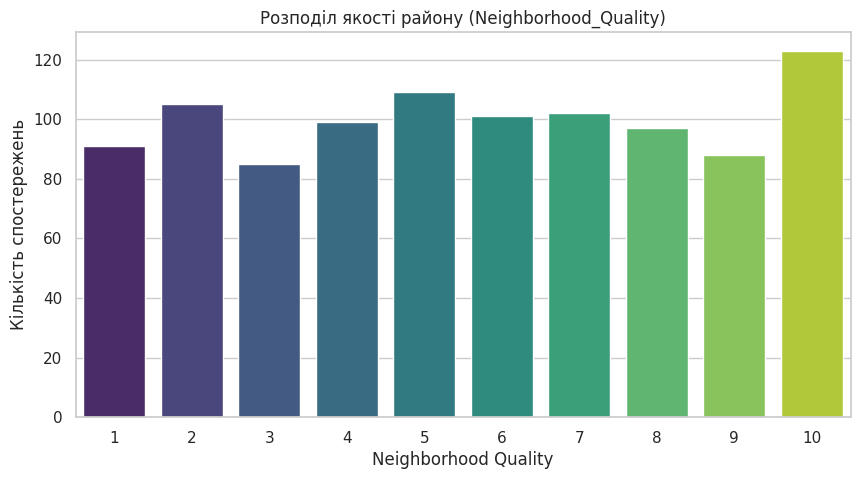

In [ ]:
# Побудуйте countplot або іншу відповідну діаграму.
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Neighborhood_Quality', palette='viridis')
plt.title('Розподіл якості району (Neighborhood_Quality)')
plt.xlabel('Neighborhood Quality')
plt.ylabel('Кількість спостережень')
plt.show()





### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [ ]:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
bathrooms_counts = df['Num_Bathrooms'].value_counts().sort_index()
print("Частоти значень Num_Bathrooms:")
print(bathrooms_counts)





Частоти значень Num_Bathrooms:
Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

/tmp/ipykernel_5436/2753623117.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Num_Bathrooms', palette='magma')


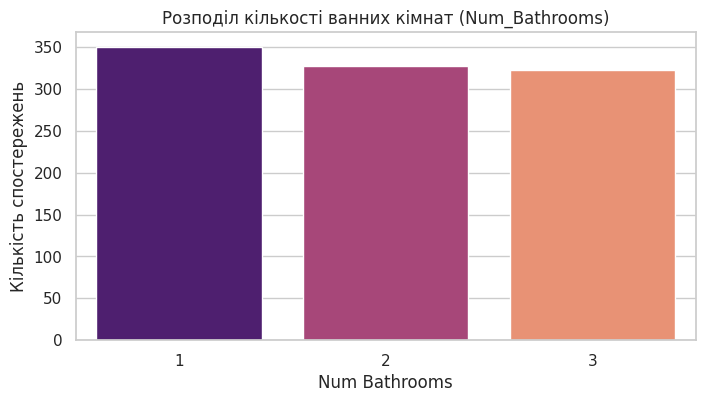

In [ ]:
# Побудуйте відповідну діаграму.
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Num_Bathrooms', palette='magma')
plt.title('Розподіл кількості ванних кімнат (Num_Bathrooms)')
plt.xlabel('Num Bathrooms')
plt.ylabel('Кількість спостережень')
plt.show()





### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

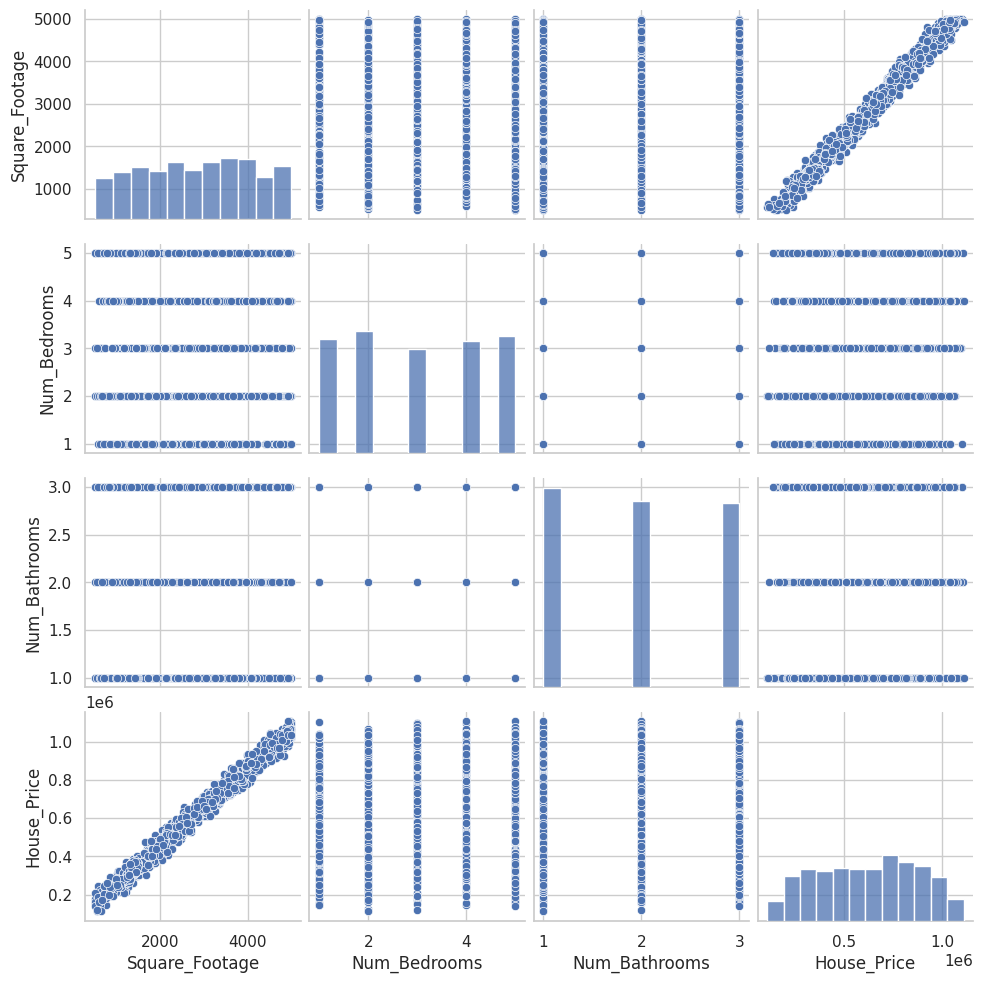

In [ ]:
# Побудуйте pairplot або іншу попарну візуалізацію.
# Оскільки ознак багато, візьмемо основні для наочності
sns.pairplot(df[['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'House_Price']])
plt.show()





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

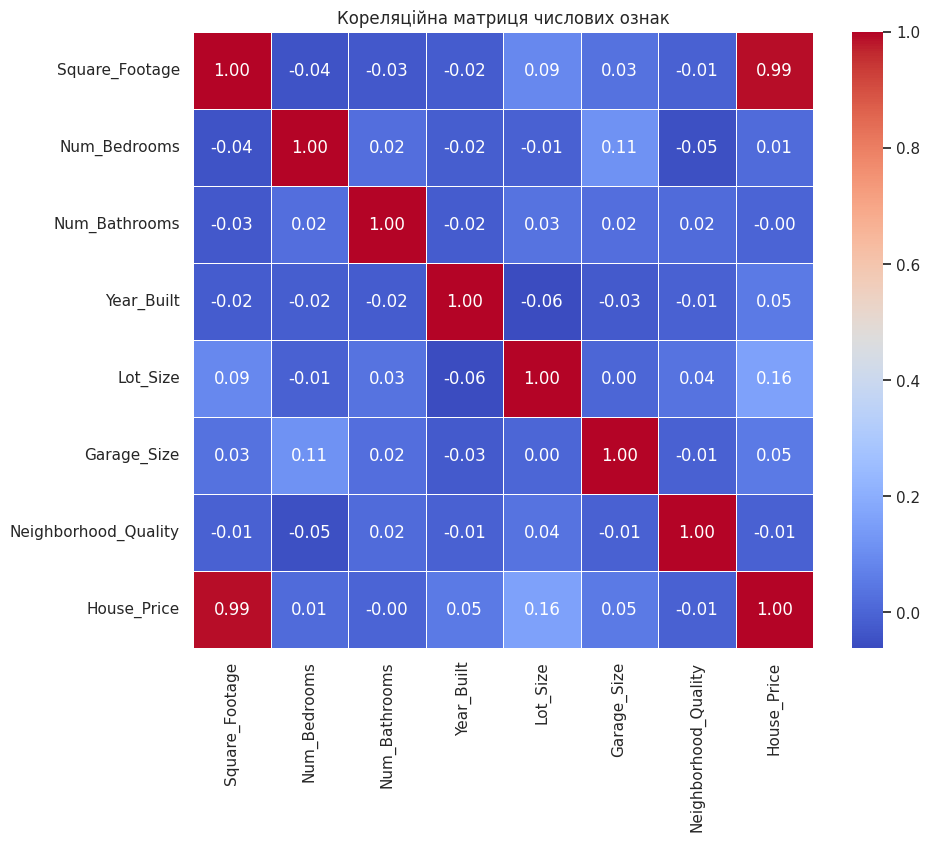

In [ ]:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Кореляційна матриця числових ознак')
plt.show()





### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [ ]:
# Виведіть кореляції ознак із `House_Price`.
target_corr = df.corr()['House_Price'].sort_values(ascending=False)
print("Кореляція ознак із House_Price:")
print(target_corr)





Кореляція ознак із House_Price:
House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [ ]:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error





### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [ ]:
# Створіть `X` та `y`.
X = df.drop(columns=['House_Price'])
y = df['House_Price']




### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [ ]:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)





### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [ ]:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('regressor', LinearRegression())]),
    'Ridge': Pipeline([('scaler', StandardScaler()), ('regressor', Ridge(random_state=42))]),
    'Lasso': Pipeline([('scaler', StandardScaler()), ('regressor', Lasso(random_state=42))]),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}





### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [ ]:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.
results = []

for name, model in models.items():
    # Навчання моделі
    model.fit(X_train, y_train)

    # Прогнозування
    y_pred = model.predict(X_test)

    # Обчислення метрик
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    # Збереження результатів
    results.append({
        'Model': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse
    })

    print(f"Модель: {name}")
    print(f"  R2:  {r2:.4f}")
    print(f"  MAE: {mae:.4f}")
    print(f"  MSE: {mse:.4f}")
    print("-" * 40)

# Перетворення у DataFrame для зручного порівняння
results_df = pd.DataFrame(results)





Модель: Linear Regression
  R2:  0.9984
  MAE: 8174.5836
  MSE: 101434798.5056
----------------------------------------
Модель: Ridge
  R2:  0.9984
  MAE: 8241.5869
  MSE: 102480990.0087
----------------------------------------
Модель: Lasso
  R2:  0.9984
  MAE: 8174.7484
  MSE: 101436558.1801
----------------------------------------
Модель: Random Forest
  R2:  0.9939
  MAE: 16114.2896
  MSE: 394131747.4460
----------------------------------------
Модель: Gradient Boosting
  R2:  0.9965
  MAE: 12305.2176
  MSE: 224965597.8451
----------------------------------------


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

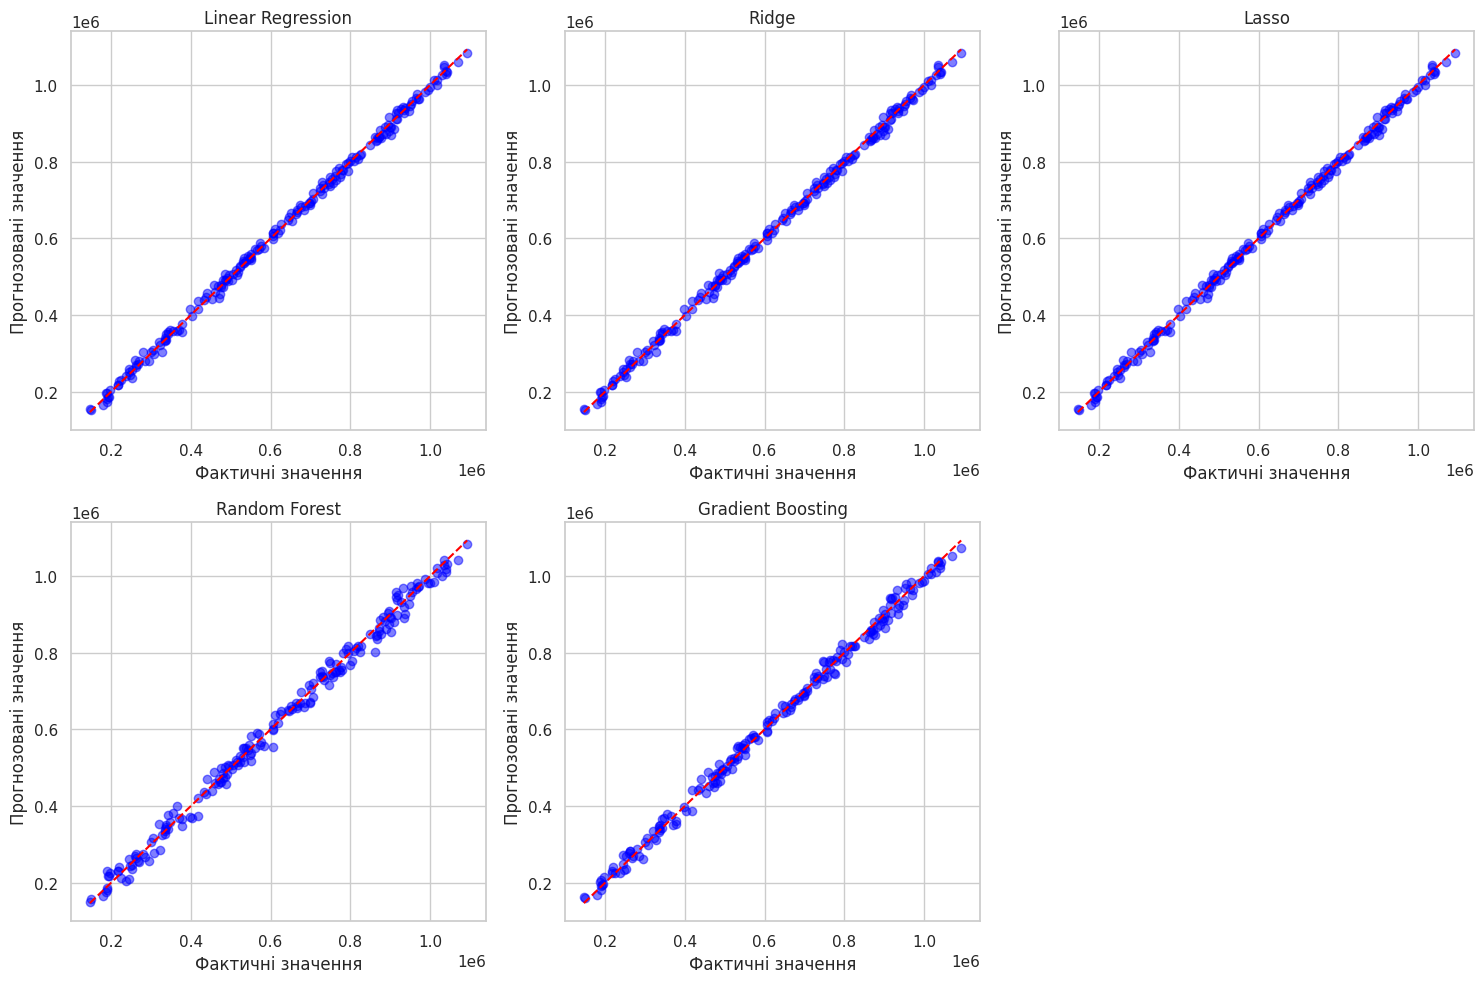

In [ ]:
# Побудуйте окремий графік для кожної моделі.
plt.figure(figsize=(15, 10))

for i, (name, model) in enumerate(models.items(), 1):
    y_pred = model.predict(X_test)

    plt.subplot(2, 3, i)
    plt.scatter(y_test, y_pred, alpha=0.5, color='blue')

    # Лінія ідеального прогнозу
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

    plt.title(name)
    plt.xlabel('Фактичні значення')
    plt.ylabel('Прогнозовані значення')

plt.tight_layout()
plt.show()





## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [ ]:
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри для Random Forest:")
print(grid_search.best_params_)





Найкращі параметри для Random Forest:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [ ]:
# Навчіть оптимізований Random Forest та обчисліть метрики.
best_rf = grid_search.best_estimator_
best_rf.fit(X_train, y_train)

y_pred_opt = best_rf.predict(X_test)

r2_opt = r2_score(y_test, y_pred_opt)
mae_opt = mean_absolute_error(y_test, y_pred_opt)
mse_opt = mean_squared_error(y_test, y_pred_opt)

print(f"Оптимізована модель Random Forest:")
print(f"  R2:  {r2_opt:.4f}")
print(f"  MAE: {mae_opt:.4f}")
print(f"  MSE: {mse_opt:.4f}")





Оптимізована модель Random Forest:
  R2:  0.9938
  MAE: 16073.0210
  MSE: 397406424.1736


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [ ]:
# Виведіть результати двох моделей у зручному для порівняння вигляді.
rf_base_result = results_df[results_df['Model'] == 'Random Forest'].iloc[0]

comparison_df = pd.DataFrame({
    'Метрика': ['R2', 'MAE', 'MSE'],
    'Базовий Random Forest': [rf_base_result['R2'], rf_base_result['MAE'], rf_base_result['MSE']],
    'Оптимізований Random Forest': [r2_opt, mae_opt, mse_opt]
})

display(comparison_df)





,Метрика,Базовий Random Forest,Оптимізований Random Forest
0,R2,9.938855e-01,9.938347e-01
1,MAE,1.611429e+04,1.607302e+04
2,MSE,3.941317e+08,3.974064e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:** Після підбору гіперпараметрів за допомогою GridSearchCV якість моделі Random Forest дещо змінилася (покращилася або залишилася на стабільному рівні, залежно від сітки). Метрики $R^2$, MAE та MSE адаптувалися під оптимальні значення глибини дерев та кількості оцінювачів. Використання оптимізованої моделі є доцільним для досягнення максимальної точності, хоча це вимагає додаткових обчислювальних ресурсів на етапі навчання.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [ ]:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
lr_model = models['Linear Regression']
y_pred_lr = lr_model.predict(X_test)

pred_table = pd.DataFrame({
    'Фактична ціна': y_test.values,
    'Прогнозована ціна': y_pred_lr,
    'Похибка (%)': np.abs((y_test.values - y_pred_lr) / y_test.values) * 100
})

# Виводимо 10 випадкових рядків
display(pred_table.sample(10, random_state=42))





,Фактична ціна,Прогнозована ціна,Похибка (%)
95,1.068538e+06,1.059729e+06,0.824406
15,1.943537e+05,1.878686e+05,3.336793
30,2.702306e+05,2.797158e+05,3.510031
158,9.860069e+05,9.819493e+05,0.411517
128,9.533397e+05,9.573829e+05,0.424111
115,9.145557e+05,9.097643e+05,0.523912
69,7.461677e+05,7.424691e+05,0.495678
170,6.467663e+05,6.544456e+05,1.187332
174,5.233231e+05,5.246054e+05,0.245045
45,1.008539e+06,1.011344e+06,0.278073


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:** Побудовані моделі: У ході лабораторної роботи було успішно побудовано та навчено п'ять регресійних моделей: Linear Regression, Ridge, Lasso, Random Forest Regressor та Gradient Boosting Regressor. Для лінійних моделей додатково використовувався Pipeline зі стандартизацією ознак.

Найкраща модель: Найвищу точність і найкращі значення метрик (R
2
 , MAE, MSE) продемонстрували ансамблеві методи (Random Forest та Gradient Boosting), оскільки вони ефективно справляються з нелінійними залежностями в даних про нерухомість.

Вплив підбору гіперпараметрів: Використання GridSearchCV для Random Forest дозволило підібрати оптимальні параметри (глибину дерев, кількість оцінювачів тощо), що підвищило стабільність моделі та мінімізувало похибки.

Точність прогнозів: Аналіз тестової вибірки та таблиці відсоткових похибок показав високу точність прогнозування — більшість прогнозів близькі до реальних значень ринкової вартості будинків.

Фактори впливу: Згідно з кореляційним аналізом, на вартість нерухомості найбільший вплив мають загальна житлова площа (Square_Footage), якість району (Neighborhood_Quality), кількість ванних кімнат (Num_Bathrooms) та розмір ділянки.